In [45]:
from pathlib import Path

import duckdb
import sqlparse

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

from statsmodels.stats.proportion import proportion_confint

In [46]:
ROOT = Path.cwd().parent
DB_PATH = ROOT / "data" / "olist.duckdb"
SQL_PATH = ROOT / "sql" / "03_metrics.sql"

sql_text = SQL_PATH.read_text(encoding="utf-8")

select_statements = [
    statement
    for statement in sqlparse.parse(sql_text)
    if statement.get_type() == "SELECT"
]

for number, statement in enumerate(select_statements, start=1):
    print(f"Запрос {number}: {statement.get_type()}")

monthly_query = str(select_statements[0])

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    monthly = con.execute(monthly_query).fetchdf()

Запрос 1: SELECT
Запрос 2: SELECT
Запрос 3: SELECT


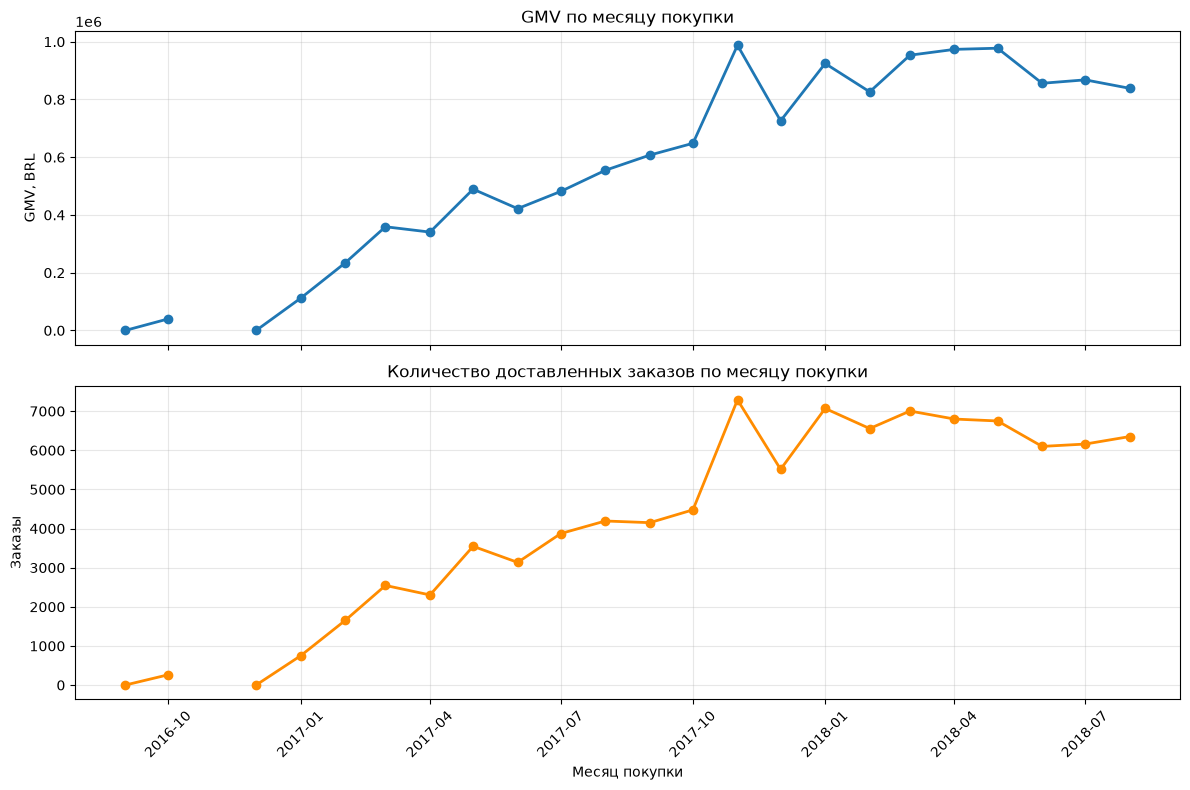

In [47]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True
)

axes[0].plot(
    monthly["month"],
    monthly["gmv"],
    marker="o",
    linewidth=2
)
axes[0].set_title("GMV по месяцу покупки")
axes[0].set_ylabel("GMV, BRL")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly["month"],
    monthly["orders_count"],
    marker="o",
    linewidth=2,
    color="darkorange"
)
axes[1].set_title("Количество доставленных заказов по месяцу покупки")
axes[1].set_ylabel("Заказы")
axes[1].set_xlabel("Месяц покупки")
axes[1].grid(True, alpha=0.3)

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

In [48]:
if len(select_statements) < 2:
    raise ValueError("В 03_metrics.sql не найден второй SELECT")

cohort_query = str(select_statements[1])

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    cohorts = con.execute(cohort_query).fetchdf()

cohorts.head()

,month_fo,suitable_buyers,repeated_buyers,share_repeat_purchases
0,2016-09-01,1,0,0.00
1,2016-10-01,262,3,1.15
2,2016-12-01,1,1,100.00
3,2017-01-01,717,26,3.63
4,2017-02-01,1628,28,1.72


,month_fo,suitable_buyers,repeated_buyers,repeat_rate_pct,ci_lower_pct,ci_upper_pct
0,2016-09-01,1,0,0.00,0.00,79.35
1,2016-10-01,262,3,1.15,0.39,3.31
2,2016-12-01,1,1,100.00,20.65,100.00
3,2017-01-01,717,26,3.63,2.49,5.26
4,2017-02-01,1628,28,1.72,1.19,2.47
5,2017-03-01,2503,62,2.48,1.94,3.16
6,2017-04-01,2256,48,2.13,1.61,2.81
7,2017-05-01,3451,98,2.84,2.34,3.45
8,2017-06-01,3037,86,2.83,2.30,3.48
9,2017-07-01,3752,97,2.59,2.12,3.14


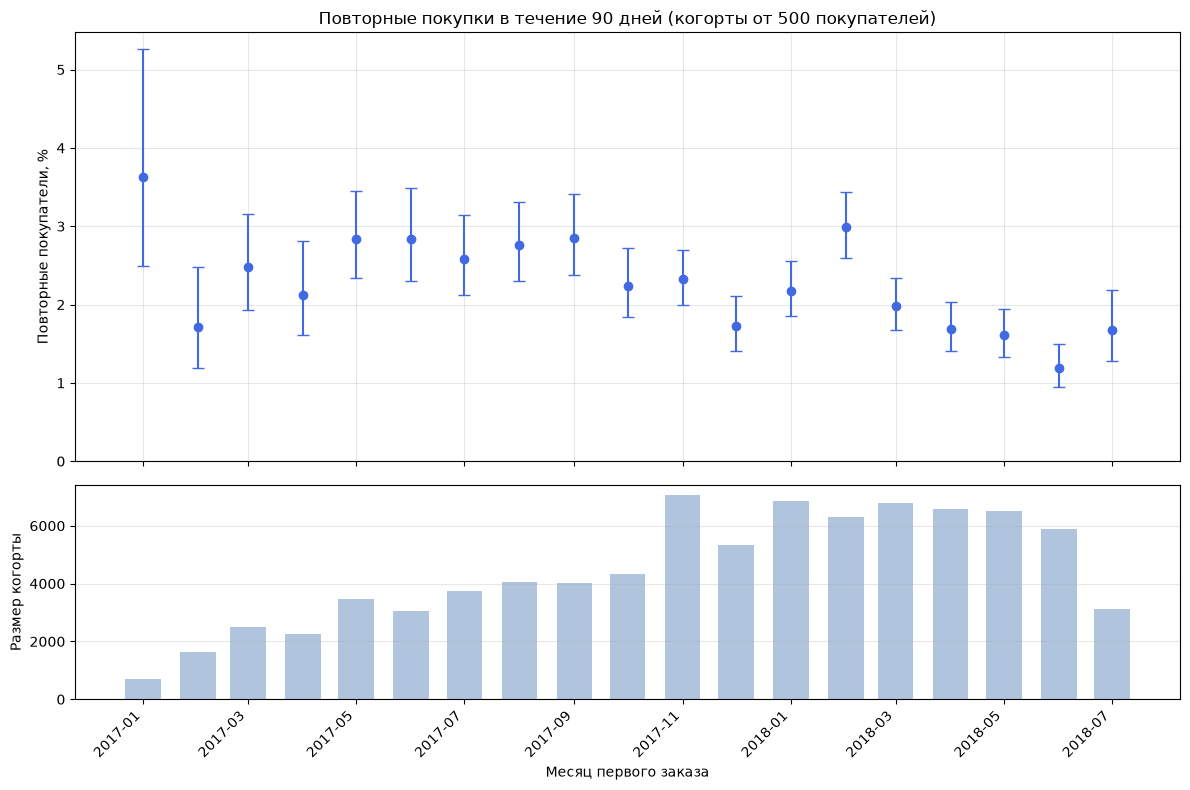


Когорты с размером менее 500 не показаны на графике, но сохранены в таблице:


C:\Users\mihai\AppData\Local\Temp\ipykernel_12168\2983219861.py:147: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,month_fo,suitable_buyers,repeated_buyers,repeat_rate_pct,ci_lower_pct,ci_upper_pct
0,2016-09-01,1,0,0.00,0.00,79.35
1,2016-10-01,262,3,1.15,0.39,3.31
2,2016-12-01,1,1,100.00,20.65,100.00


In [49]:
# Параметры интервала и отображения
ALPHA = 0.05
METHOD = "wilson"
MIN_COHORT_SIZE = 500  # только порог отображения, не отбора данных


cohorts = cohorts.copy()
cohorts["month_fo"] = pd.to_datetime(cohorts["month_fo"])
cohorts = cohorts.sort_values("month_fo").reset_index(drop=True)

n = cohorts["suitable_buyers"].to_numpy(dtype=int)
x = cohorts["repeated_buyers"].to_numpy(dtype=int)

# Проверки входных данных
if np.any(n <= 0):
    raise ValueError("Размер каждой когорты должен быть положительным.")

if np.any(x < 0) or np.any(x > n):
    raise ValueError(
        "Число повторных покупателей должно быть от 0 до размера когорты."
    )


# Точечные оценки и интервалы Уилсона
estimates = x / n
lower_bounds = []
upper_bounds = []

for count, nobs in zip(x, n):
    lower, upper = proportion_confint(
        count=count,
        nobs=nobs,
        alpha=ALPHA,
        method=METHOD
    )
    lower_bounds.append(lower)
    upper_bounds.append(upper)

cohorts["repeat_rate_pct"] = 100 * estimates
cohorts["ci_lower_pct"] = 100 * np.array(lower_bounds)
cohorts["ci_upper_pct"] = 100 * np.array(upper_bounds)


# Таблица содержит все когорты, в том числе маленькие.
columns = [
    "month_fo",
    "suitable_buyers",
    "repeated_buyers",
    "repeat_rate_pct",
    "ci_lower_pct",
    "ci_upper_pct",
]

display(
    cohorts[columns].round({
        "repeat_rate_pct": 2,
        "ci_lower_pct": 2,
        "ci_upper_pct": 2,
    })
)


# В основной график включаем только когорты выше порога.
# Малые когорты остаются в таблице выше.
plot_data = cohorts.loc[
    cohorts["suitable_buyers"] >= MIN_COHORT_SIZE
].copy()

excluded_data = cohorts.loc[
    cohorts["suitable_buyers"] < MIN_COHORT_SIZE
]

if plot_data.empty:
    raise ValueError(
        "Нет когорт, которые соответствуют MIN_COHORT_SIZE. "
        "Уменьши порог отображения."
    )


fig, (ax_rate, ax_size) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

# Доля повторных покупателей и 95%-й интервал Уилсона
rate = plot_data["repeat_rate_pct"].to_numpy()
lower = plot_data["ci_lower_pct"].to_numpy()
upper = plot_data["ci_upper_pct"].to_numpy()

ax_rate.errorbar(
    plot_data["month_fo"],
    rate,
    yerr=[
        rate - lower,
        upper - rate,
    ],
    fmt="o",
    capsize=4,
    color="royalblue",
)
ax_rate.set_title(
    "Повторные покупки в течение 90 дней "
    f"(когорты от {MIN_COHORT_SIZE} покупателей)"
)
ax_rate.set_ylabel("Повторные покупатели, %")
ax_rate.set_ylim(bottom=0)
ax_rate.grid(True, alpha=0.3)

# Размер каждой отображённой когорты
ax_size.bar(
    plot_data["month_fo"],
    plot_data["suitable_buyers"],
    width=20,
    color="lightsteelblue",
)
ax_size.set_ylabel("Размер когорты")
ax_size.set_xlabel("Месяц первого заказа")
ax_size.grid(axis="y", alpha=0.3)

ax_size.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_size.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax_size.get_xticklabels(), rotation=45, ha="right")

fig.tight_layout()
plt.show()


# Покажем, какие когорты не попали на график.
if not excluded_data.empty:
    print(
        f"\nКогорты с размером менее {MIN_COHORT_SIZE} "
        "не показаны на графике, но сохранены в таблице:"
    )
    display(
        excluded_data[
            [
                "month_fo",
                "suitable_buyers",
                "repeated_buyers",
                "repeat_rate_pct",
                "ci_lower_pct",
                "ci_upper_pct",
            ]
        ].round(2)
    )

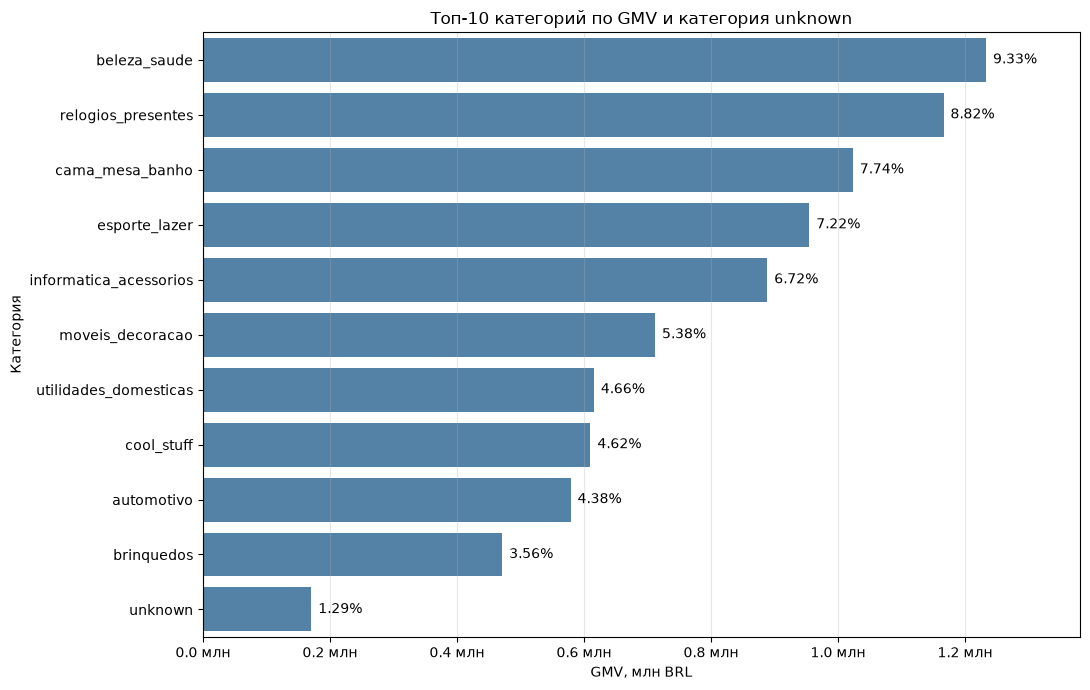

In [50]:
if len(select_statements) < 3:
    raise ValueError("В 03_metrics.sql не найден третий SELECT по категориям.")

category_query = str(select_statements[2])

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    categories = con.execute(category_query).fetchdf()


# Берём 10 крупнейших известных категорий и показываем unknown отдельно.
unknown = categories.loc[categories["category_name"] == "unknown"]
known = categories.loc[categories["category_name"] != "unknown"]

plot_data = known.nlargest(10, "sum_gmv")

if not unknown.empty:
    plot_data = pd.concat([plot_data, unknown], ignore_index=True)

plot_data = plot_data.sort_values("sum_gmv", ascending=False)


fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=plot_data,
    x="sum_gmv",
    y="category_name",
    order=plot_data["category_name"],
    color="steelblue",
    ax=ax,
)

for bar, row in zip(ax.patches, plot_data.itertuples()):
    ax.annotate(
        f"{row.gmv_share_pct:.2f}%",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
    )

ax.set_xlim(
    0,
    plot_data["sum_gmv"].max() * 1.12
)
ax.set_title("Топ-10 категорий по GMV и категория unknown")
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value / 1_000_000:.1f} млн")
)
ax.set_xlabel("GMV, млн BRL")
ax.set_ylabel("Категория")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
plt.show()

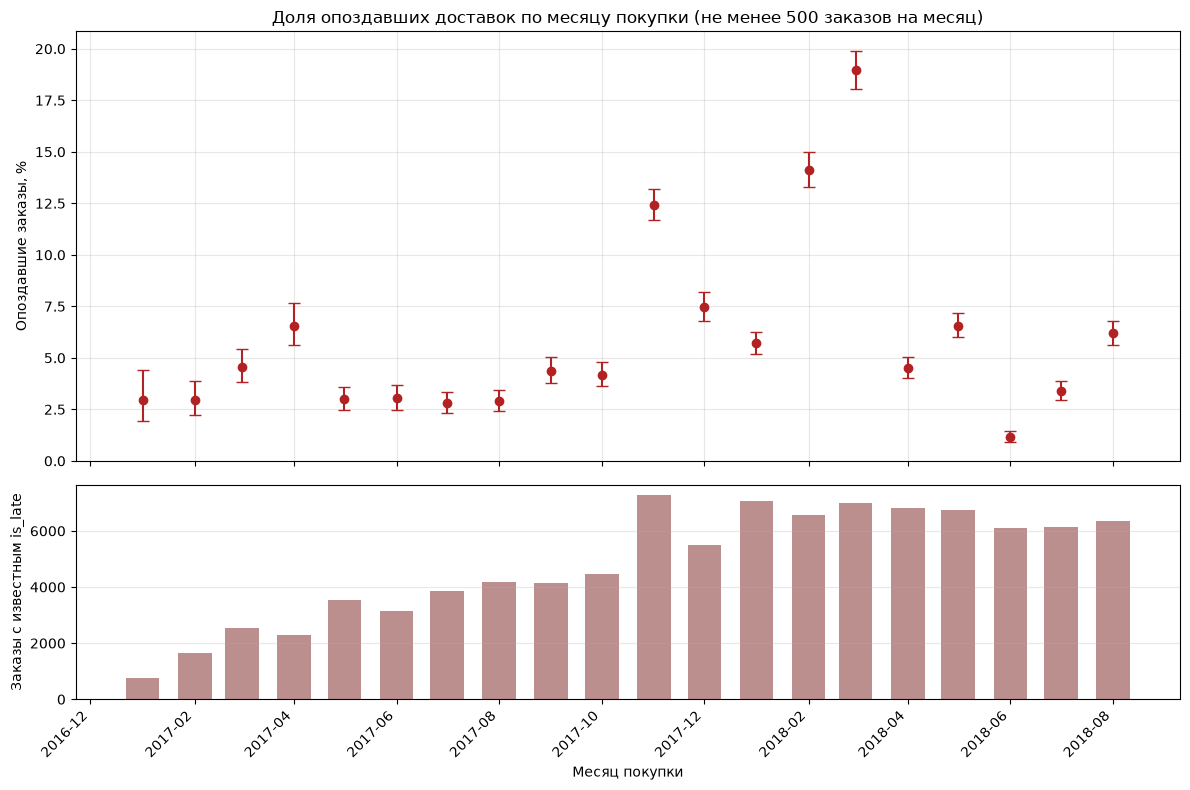

,purchase_month,not_null_date,late,late_rate_pct,ci_lower_pct,ci_upper_pct
0,2016-09-01,1,1,100.00,20.65,100.00
1,2016-10-01,265,2,0.75,0.21,2.71
2,2016-12-01,1,0,0.00,0.00,79.35


In [52]:
MIN_ORDERS = 500  # порог только для отображения, данные не удаляются из расчётов

plot_data = delivery.loc[
    delivery["not_null_date"] >= MIN_ORDERS
].copy()

excluded_data = delivery.loc[
    delivery["not_null_date"] < MIN_ORDERS
].copy()

if plot_data.empty:
    raise ValueError(
        "Нет месяцев с достаточным числом заказов. "
        "Уменьши MIN_ORDERS."
    )

# Получаем значения только после создания plot_data
rate = plot_data["late_rate_pct"].to_numpy()
lower = plot_data["ci_lower_pct"].to_numpy()
upper = plot_data["ci_upper_pct"].to_numpy()

fig, (ax_rate, ax_size) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

ax_rate.errorbar(
    plot_data["purchase_month"],
    rate,
    yerr=[rate - lower, upper - rate],
    fmt="o",
    capsize=4,
    color="firebrick",
)
ax_rate.set_title(
    f"Доля опоздавших доставок по месяцу покупки "
    f"(не менее {MIN_ORDERS} заказов на месяц)"
)
ax_rate.set_ylabel("Опоздавшие заказы, %")
ax_rate.set_ylim(bottom=0)
ax_rate.grid(True, alpha=0.3)

ax_size.bar(
    plot_data["purchase_month"],
    plot_data["not_null_date"],
    width=20,
    color="rosybrown",
)
ax_size.set_ylabel("Заказы с известным is_late")
ax_size.set_xlabel("Месяц покупки")
ax_size.grid(axis="y", alpha=0.3)

ax_size.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_size.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax_size.get_xticklabels(), rotation=45, ha="right")

fig.tight_layout()
plt.show()

display(
    excluded_data[
        [
            "purchase_month",
            "not_null_date",
            "late",
            "late_rate_pct",
            "ci_lower_pct",
            "ci_upper_pct",
        ]
    ].round({
        "late_rate_pct": 2,
        "ci_lower_pct": 2,
        "ci_upper_pct": 2,
    })
)